<a href="https://colab.research.google.com/github/RohitRevankarDev/AML-Assignment-261100610035/blob/main/2a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Distance Metrics and Clustering Algorithms

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

def euclidean_distance(a, b):
    a, b = np.array(a), np.array(b)
    return np.sqrt(np.sum((a - b) ** 2))


def manhattan_distance(a, b):
    a, b = np.array(a), np.array(b)
    return np.sum(np.abs(a - b))


def cosine_similarity(a, b):
    a, b = np.array(a), np.array(b)
    denominator = np.linalg.norm(a) * np.linalg.norm(b)

    if denominator == 0:
        return np.nan

    return np.dot(a, b) / denominator


point_a = [1, 2, 3]
point_b = [2, 4, 5]

print("Euclidean Distance:", round(euclidean_distance(point_a, point_b), 4))
print("Manhattan Distance:", manhattan_distance(point_a, point_b))
print("Cosine Similarity:", round(cosine_similarity(point_a, point_b), 4))


Euclidean Distance: 3.0
Manhattan Distance: 5
Cosine Similarity: 0.996


In [3]:

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset shape:", X.shape)
print("Features:", list(X.columns))
print("Number of samples:", len(X))
print("Number of classes:", len(np.unique(y)))


Dataset shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Number of samples: 150
Number of classes: 3


In [4]:

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-means clustering completed.")
print("Inertia:", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(silhouette_score(X_scaled, kmeans_labels), 4))
print("Adjusted Rand Index:", round(adjusted_rand_score(y, kmeans_labels), 4))

print("\nCluster Centers:")
display(pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X.columns
).round(3))


K-means clustering completed.
Inertia: 139.8205
Silhouette Score: 0.4599
Adjusted Rand Index: 0.6201

Cluster Centers:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.050,-0.883,0.348,0.282
1,-1.015,0.853,-1.305,-1.255
2,1.136,0.088,0.996,1.018


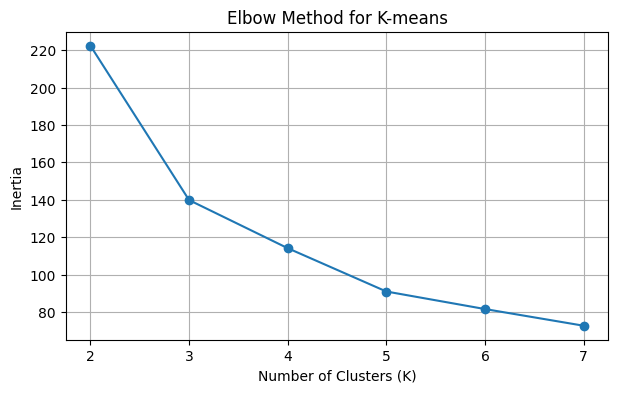

In [5]:

inertias = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


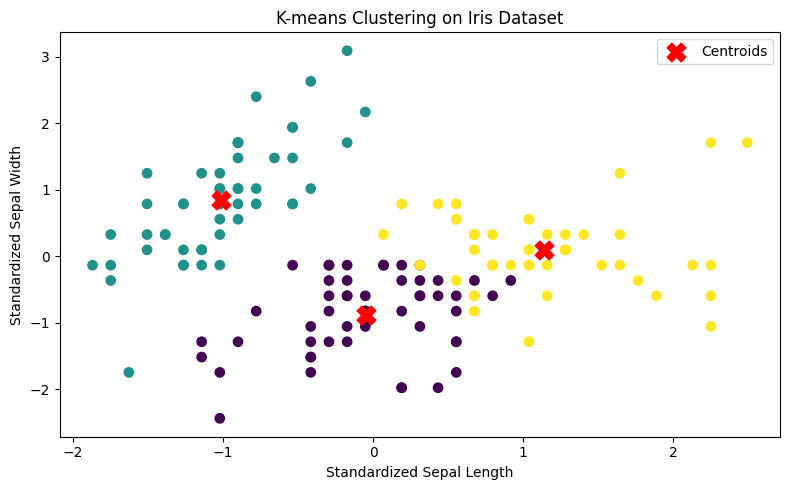

In [6]:

plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=45
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=180,
    label="Centroids"
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("K-means Clustering on Iris Dataset")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:

linkage_methods = ["single", "complete", "average", "ward"]
hierarchical_results = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=3,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_results.append({
        "Linkage Method": method,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Adjusted Rand Index": adjusted_rand_score(y, labels)
    })

hierarchical_df = pd.DataFrame(hierarchical_results)

display(hierarchical_df.round(4))


,Linkage Method,Silhouette Score,Adjusted Rand Index
0,single,0.5046,0.5584
1,complete,0.4496,0.5726
2,average,0.4803,0.5621
3,ward,0.4467,0.6153


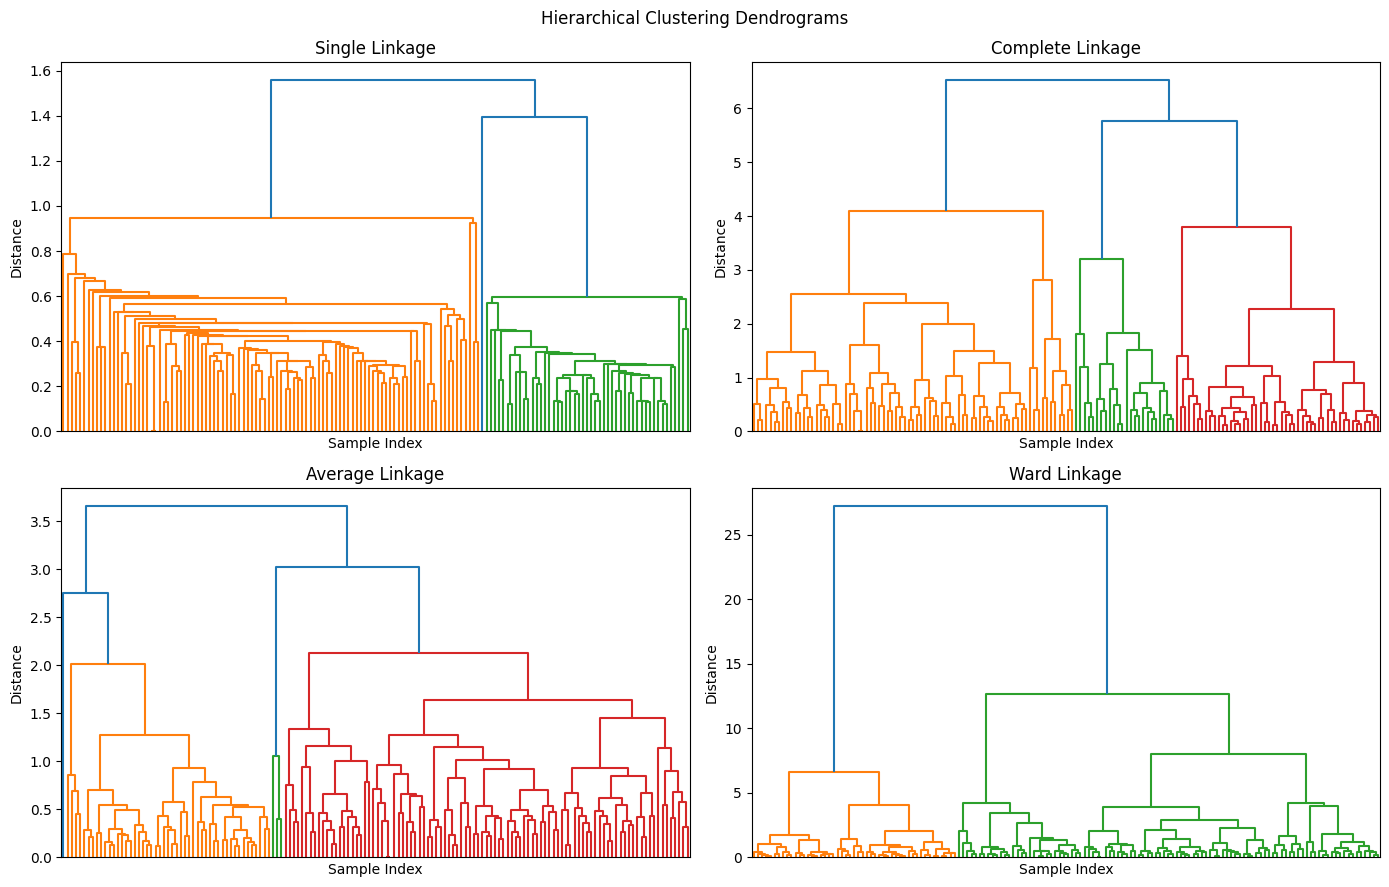

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, method in zip(axes.flatten(), linkage_methods):
    linkage_matrix = linkage(X_scaled, method=method)

    dendrogram(
        linkage_matrix,
        ax=ax,
        no_labels=True
    )

    ax.set_title(method.capitalize() + " Linkage")
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Distance")

plt.suptitle("Hierarchical Clustering Dendrograms")
plt.tight_layout()
plt.show()



## Result

Euclidean distance, Manhattan distance and Cosine similarity were calculated. K-means clustering was implemented on the Iris dataset, and the elbow method was used to study different cluster counts. Hierarchical clustering was performed using single, complete, average and Ward linkage methods. Cluster performance was evaluated using Silhouette Score and Adjusted Rand Index, and dendrograms were plotted.

## Conclusion

The experiment demonstrates distance-based clustering using K-means and hierarchical clustering. The results show how different clustering methods and linkage criteria can produce different groupings of the same dataset.
